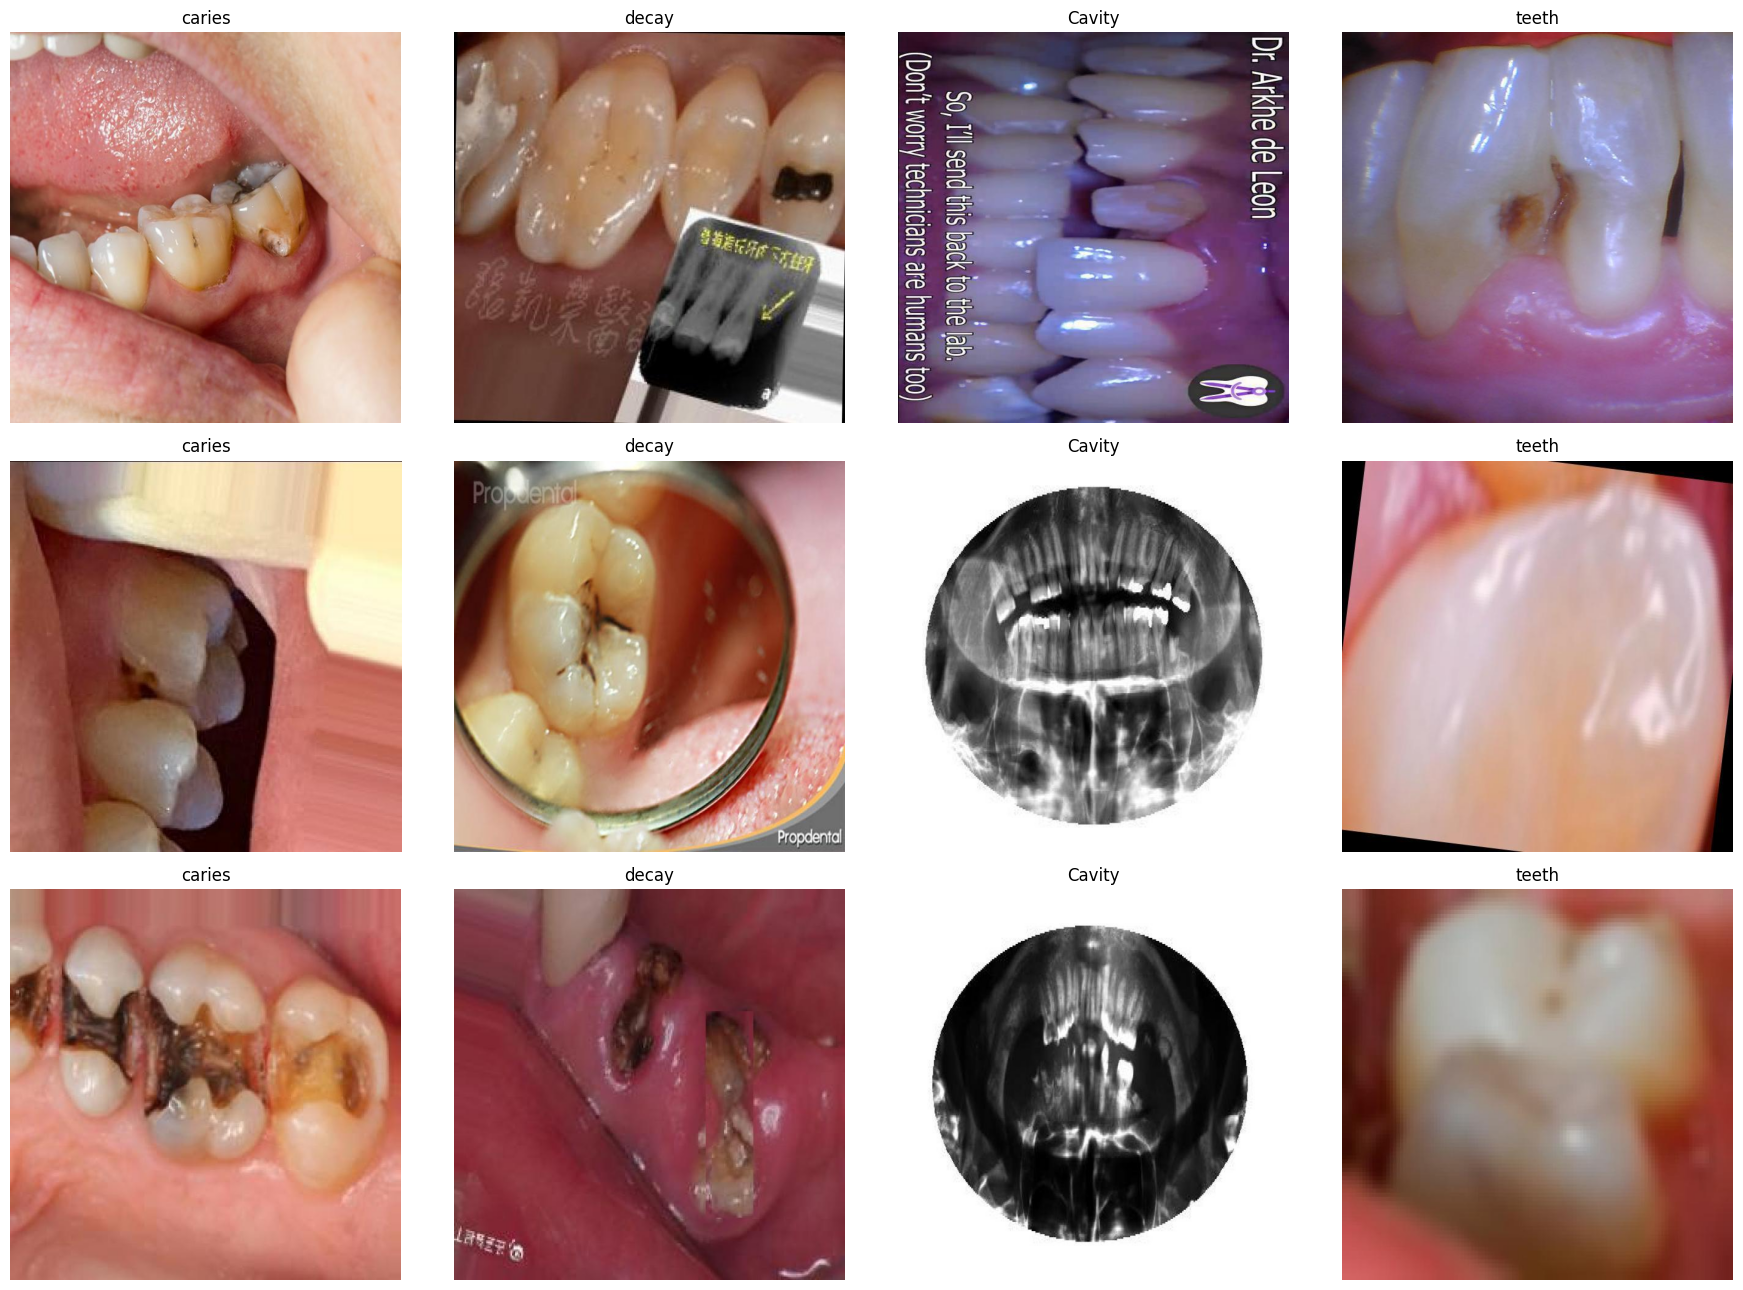

In [1]:
import os, random
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

RB = r"D:\Data Mining\Dataset\roboflow_dental_project"
d = pd.read_csv(os.path.join(RB, "train", "_classes.csv"))
d.columns = [c.strip() for c in d.columns]
fn = d.columns[0]

random.seed(1)
pilih = []
for kls in ["caries", "decay", "Cavity", "teeth"]:
    idx = d.index[d[kls] == 1].tolist()
    pilih += [(kls, i) for i in random.sample(idx, 3)]

fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for ax, (kls, i) in zip(axes.T.flatten(), pilih):
    ax.imshow(Image.open(os.path.join(RB, "train", d.loc[i, fn])))
    ax.set_title(kls)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [2]:
import numpy as np

frames = []
for sp in ["train", "valid", "test"]:
    t = pd.read_csv(os.path.join(RB, sp, "_classes.csv"))
    t.columns = [c.strip() for c in t.columns]
    t = t.rename(columns={t.columns[0]: "file"})
    t["split_asal"] = sp
    frames.append(t)
rb = pd.concat(frames, ignore_index=True)
kelas = [c for c in rb.columns if c not in ("file", "split_asal")]

print("caries:", rb["caries"].sum(), "| decay:", rb["decay"].sum(),
      "| keduanya:", int(((rb["caries"] == 1) & (rb["decay"] == 1)).sum()))

kand = rb[(rb["caries"] == 1) | (rb["decay"] == 1)].copy()
kand["path"] = [os.path.join(RB, s, f) for s, f in zip(kand["split_asal"], kand["file"])]
print("kandidat (caries atau decay):", len(kand))
print()
print("label lain yang ikut menempel pada kandidat:")
print(kand[kelas].sum().to_string())

def skor_warna(p):
    a = np.asarray(Image.open(p).convert("RGB").resize((64, 64))).astype(int)
    return np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()

kand["warna"] = [skor_warna(p) for p in kand["path"]]
print()
print("gambar hampir abu-abu (warna < 5):", int((kand["warna"] < 5).sum()))
print(kand["warna"].describe().to_string())

caries: 2291 | decay: 2333 | keduanya: 0
kandidat (caries atau decay): 4624

label lain yang ikut menempel pada kandidat:
Cavity              61
Fillings             0
Implant              0
caries            2291
decay             2333
earlydecay           0
infected-teeth       0
teeth                0

gambar hampir abu-abu (warna < 5): 0
count    4624.000000
mean       62.191300
std        21.885056
min        13.896484
25%        45.974365
50%        60.383911
75%        77.236389
max       179.149902


In [3]:
import numpy as np, imagehash
from PIL import ImageOps
from tqdm import tqdm

# buang 61 gambar yang menempel dengan Cavity
kand = kand[kand["Cavity"] == 0].copy().reset_index(drop=True)
kand["sumber_label"] = np.where(kand["caries"] == 1, "caries", "decay")
print("kandidat setelah buang Cavity:", len(kand))

def dua_hash(p):
    im = Image.open(p).convert("RGB")
    a = imagehash.phash(im).hash.flatten().astype(np.uint8)
    b = imagehash.phash(ImageOps.mirror(im)).hash.flatten().astype(np.uint8)
    return a, b

R, Rf = [], []
for p in tqdm(kand["path"]):
    a, b = dua_hash(p)
    R.append(a); Rf.append(b)
R, Rf = np.array(R), np.array(Rf)
np.save("hash_rb.npy", R); np.save("hash_rb_f.npy", Rf)

def ham(P, Q):
    P, Q = P.astype(np.float32), Q.astype(np.float32)
    return (P.shape[1] - (P @ Q.T + (1 - P) @ (1 - Q).T)).round().astype(np.int16)

# 1) kelompok di dalam data Roboflow sendiri (ambang 6)
D = np.minimum(ham(R, R), ham(R, Rf))
par = list(range(len(R)))
def f(x):
    while par[x] != x:
        par[x] = par[par[x]]; x = par[x]
    return x
ii, jj = np.where(np.triu(D <= 6, k=1))
for a, b in zip(ii, jj):
    ra, rb_ = f(a), f(b)
    if ra != rb_: par[rb_] = ra
kand["grup_rb"] = [f(i) for i in range(len(R))]

print()
print("kelompok unik Roboflow:", kand["grup_rb"].nunique(), "dari", len(kand), "gambar")
print(kand.groupby("sumber_label")["grup_rb"].nunique().to_string())

# 2) tumpang tindih dengan data Kaggle
kg = pd.read_csv("df_semua_ambang6.csv")
KA, KAf = np.load("hash_A.npy"), np.load("hash_Af.npy")
DK = np.minimum(ham(R, KA), ham(R, KAf))
terdekat = DK.min(axis=1)
idx = DK.argmin(axis=1)
mirip = terdekat <= 6
print()
print("gambar Roboflow yang mirip gambar Kaggle (jarak <= 6):", int(mirip.sum()))
print("label Kaggle dari kembarannya:")
print(kg.loc[idx[mirip], "label"].value_counts().to_string())

kand.to_csv("kandidat_rb.csv", index=False)

kandidat setelah buang Cavity: 4563


100%|██████████| 4563/4563 [00:31<00:00, 143.09it/s]



kelompok unik Roboflow: 3317 dari 4563 gambar
sumber_label
caries    1993
decay     1964

gambar Roboflow yang mirip gambar Kaggle (jarak <= 6): 22
label Kaggle dari kembarannya:
label
caries        21
gingivitis     1


In [4]:
kand["mirip_kaggle"] = mirip

g = kand.groupby("grup_rb")["sumber_label"].nunique()
print("kelompok Roboflow berisi caries DAN decay:", int((g > 1).sum()))

rb_car = kand[(kand["sumber_label"] == "caries") & (~kand["mirip_kaggle"])].copy()
print("caries Roboflow tanpa kembaran Kaggle:", len(rb_car), "gambar,",
      rb_car["grup_rb"].nunique(), "kelompok")

rng = np.random.default_rng(42)
dipilih = rng.choice(rb_car["grup_rb"].unique(), size=400, replace=False)
rb_car = rb_car[rb_car["grup_rb"].isin(dipilih)]

kaggle = pd.read_csv("data_bersih_ambang6.csv")
kaggle["source"] = "kaggle"
kaggle["grup"] = "k" + kaggle["group6"].astype(str)

rb_out = pd.DataFrame({
    "path": rb_car["path"],
    "label": "caries",
    "source": "roboflow",
    "grup": "r" + rb_car["grup_rb"].astype(str),
})

gab = pd.concat([kaggle[["path", "label", "source", "grup"]], rb_out], ignore_index=True)

print()
print("gambar per kelas dan sumber:")
print(pd.crosstab(gab["label"], gab["source"]))
print()
print("kelompok unik per kelas:")
print(gab.groupby("label")["grup"].nunique().to_string())
print("total:", len(gab), "gambar,", gab["grup"].nunique(), "kelompok")

gab.to_csv("gabungan_ambang6.csv", index=False)

kelompok Roboflow berisi caries DAN decay: 640
caries Roboflow tanpa kembaran Kaggle: 2279 gambar, 1983 kelompok

gambar per kelas dan sumber:
source      kaggle  roboflow
label                       
calculus       575         0
caries         205       465
gingivitis    1583         0

kelompok unik per kelas:
label
calculus      218
caries        580
gingivitis    590
total: 2828 gambar, 1388 kelompok


In [5]:
import numpy as np, pandas as pd

gab = pd.read_csv("gabungan_ambang6.csv")

cek = gab.groupby("grup")["label"].nunique()
print("kelompok dengan lebih dari 1 label:", int((cek > 1).sum()))

rng = np.random.default_rng(42)
split_of = {}
for kls, sub in gab.groupby("label"):
    ids = sub["grup"].unique()
    rng.shuffle(ids)
    n = len(ids)
    n_tr = int(round(n * 0.70))
    n_va = int(round(n * 0.15))
    for i, gid in enumerate(ids):
        split_of[gid] = "train" if i < n_tr else ("val" if i < n_tr + n_va else "test")

gab["split"] = gab["grup"].map(split_of)

bocor = gab.groupby("grup")["split"].nunique()
print("kelompok yang muncul di lebih dari 1 split:", int((bocor > 1).sum()))
print()
print("gambar per kelas dan split:")
print(pd.crosstab(gab["label"], gab["split"])[["train", "val", "test"]])
print()
print("gambar per kelas, sumber, dan split:")
print(pd.crosstab([gab["label"], gab["source"]], gab["split"])[["train", "val", "test"]])
print()
print("kelompok per split:")
print(gab.groupby("split")["grup"].nunique().to_string())

gab.to_csv("split_ambang6.csv", index=False)

kelompok dengan lebih dari 1 label: 0
kelompok yang muncul di lebih dari 1 split: 0

gambar per kelas dan split:
split       train  val  test
label                       
calculus      434   92    49
caries        456  109   105
gingivitis   1076  244   263

gambar per kelas, sumber, dan split:
split                train  val  test
label      source                    
calculus   kaggle      434   92    49
caries     kaggle      151   23    31
           roboflow    305   86    74
gingivitis kaggle     1076  244   263

kelompok per split:
split
test     208
train    972
val      208


C:\Users\HP VICTUS\AppData\Local\Temp\ipykernel_8444\1099908072.py:12: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(ids)


In [6]:
import numpy as np, pandas as pd

gab = pd.read_csv("gabungan_ambang6.csv")

rng = np.random.default_rng(42)
split_of = {}
for kls, sub in gab.groupby("label"):
    ids = rng.permutation(sorted(sub["grup"].unique()))
    n = len(ids)
    n_tr = int(round(n * 0.70))
    n_va = int(round(n * 0.15))
    for i, gid in enumerate(ids):
        split_of[gid] = "train" if i < n_tr else ("val" if i < n_tr + n_va else "test")

gab["split"] = gab["grup"].map(split_of)

assert gab["split"].notna().all(), "ada baris tanpa split"
assert gab.groupby("grup")["split"].nunique().max() == 1, "ada kelompok bocor"
assert gab.groupby("grup")["label"].nunique().max() == 1, "ada kelompok campur"
print("semua pengecekan lolos, total:", len(gab), "gambar")
print()
print(pd.crosstab(gab["label"], gab["split"])[["train", "val", "test"]])
print()
print(pd.crosstab([gab["label"], gab["source"]], gab["split"])[["train", "val", "test"]])

gab.to_csv("split_ambang6.csv", index=False)

semua pengecekan lolos, total: 2828 gambar

split       train  val  test
label                       
calculus      414   81    80
caries        463  107   100
gingivitis   1145  209   229

split                train  val  test
label      source                    
calculus   kaggle      414   81    80
caries     kaggle      151   23    31
           roboflow    312   84    69
gingivitis kaggle     1145  209   229
